# Notebook 4 — Baseline Decision Tree (instructions only)

**Research Project:** Lightweight Machine Learning-Based Cybersecurity Threat Detection for Resource-Constrained Hardware
**Author:** Anush Jindal

**There is no code in this notebook on purpose.** Each step tells you *what* to do, *what to use*, and *how to know it worked*. You write the code in the empty cells. If you get stuck, read the linked documentation, check `PIPELINE_CHEATSHEET.ipynb`, and ask.

## The goal of this stage

Train the simplest possible model (a Decision Tree with **no tuning**) on each of your four clue lists (A, B, C, D). Record how well it scores and how big and slow it is. This is the **baseline**: the reference point we try to shrink later.

## Three rules

1. **Learn from `X_train` only.** `X_test` is the exam. Use it to score, never to choose clues or settings.
2. **Don't tune anything yet.** No `max_depth`, no pruning. That is a later stage.
3. **Write down the numbers you actually get.** Never a guessed number.

## Steps

1. Setup
2. Load your data and your four clue lists
3. Test your own keep/remove claims
4. Train on clue list A and score it
5. Compare A, B, C, D
6. Shortcut check
7. Save your results
8. Read your numbers honestly

## Step 1 — Setup

**Goal:** load the tools and tell the notebook where your files are.

**What to do:**
- Import `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn` and `joblib`.
- From scikit-learn, import `DecisionTreeClassifier` (from `sklearn.tree`) and these from `sklearn.metrics`: `accuracy_score`, `precision_recall_fscore_support`, `classification_report`, `confusion_matrix`.
- Also import the standard modules `os`, `time`, `json` and `datetime`.
- In Colab, mount your Google Drive and save the path of the folder with your data files (the same folder you used in Notebook 3) in a variable.

**Docs:** [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) · [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)

**You're done when:** the cell runs with no error and printing your folder path shows the right place.

In [ ]:
# Step 1 — Setup
import os
import time
import json
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

%matplotlib inline

# Mount Google Drive (only works inside Colab; skipped if you run this locally)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab, so Drive was not mounted.")

# Same folder Notebook 3 saved into
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/threat detector")
DATA_DIR    = PROJECT_DIR / "data"          # inputs from Notebook 3
MODEL_DIR   = PROJECT_DIR / "models"        # saved trees (.joblib) go here
RESULTS_DIR = PROJECT_DIR / "experiments"   # results CSV + figures go here
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Data folder:", DATA_DIR)
print("Files in it:", sorted(p.name for p in DATA_DIR.iterdir()))

Mounted at /content/drive
Data folder: /content/drive/MyDrive/Colab Notebooks/threat detector/data
Files in it: ['X_test.csv', 'X_test_engineered.csv', 'X_train.csv', 'X_train_engineered.csv', 'feature_sets.json', 'y_test.csv', 'y_train.csv']


## Step 2 — Load your data and your four clue lists

**Goal:** get the study pile, the exam pile and your four lists of column names into the notebook.

**What to do:** load these five files from your data folder:

| File | What it is |
|---|---|
| `X_train_engineered.csv` | the clues for the study pile |
| `X_test_engineered.csv` | the clues for the exam pile |
| `y_train.csv` | the answer key for the study pile |
| `y_test.csv` | the answer key for the exam pile |
| `feature_sets.json` | your lists A, B, C, D |

**Tips:**
- The two `y` files each have one column. You want a plain list of labels, not a one-column table. Look up what pandas calls turning a one-column table into a single column (hint: `squeeze`).
- Use the `json` module to read the clue lists.

**Checks to run (print or assert them):**
- The shapes match your notes from Notebook 2.
- The four lists have **57, 39, 15 and 6** names.
- Train and test have the same columns in the same order.
- Every name in every list really exists in `X_train`.
- Count the labels in `y_train`. Make sure the exact text `BENIGN` is one of them.

**You're done when:** every check passes. If one fails, stop and fix it before moving on.

In [ ]:
# Step 2 — Load the data and the four clue lists
X_train = pd.read_csv(DATA_DIR / "X_train_engineered.csv")
X_test  = pd.read_csv(DATA_DIR / "X_test_engineered.csv")
# squeeze("columns") turns the one-column table into a plain Series of labels
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

with open(DATA_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)

print("X_train:", X_train.shape, "  X_test:", X_test.shape)
print("y_train:", y_train.shape, "  y_test:", y_test.shape)
print("Clue list sizes:", {name: len(cols) for name, cols in feature_sets.items()})

# ---------------- Checks ----------------
# 1. Shapes match the notes from Notebook 2 (experiment_notes.md, 6-10-2026)
EXPECTED_TRAIN_SHAPE = (488393, 78)
EXPECTED_TEST_SHAPE  = (122099, 78)
assert X_train.shape == EXPECTED_TRAIN_SHAPE, f"X_train is {X_train.shape}, notes say {EXPECTED_TRAIN_SHAPE}"
assert X_test.shape == EXPECTED_TEST_SHAPE, f"X_test is {X_test.shape}, notes say {EXPECTED_TEST_SHAPE}"
assert isinstance(y_train, pd.Series) and isinstance(y_test, pd.Series), "y files did not squeeze to a Series"
assert len(y_train) == len(X_train) and len(y_test) == len(X_test), "X and y row counts differ"

# 2. The four lists have 57, 39, 15 and 6 names (and no name appears twice)
EXPECTED_SIZES = {"A": 57, "B": 39, "C": 15, "D": 6}
for name, n in EXPECTED_SIZES.items():
    assert len(feature_sets[name]) == n, f"List {name} has {len(feature_sets[name])} names, expected {n}"
    assert len(set(feature_sets[name])) == n, f"List {name} has a repeated name"

# 3. Train and test have the same columns in the same order
assert list(X_train.columns) == list(X_test.columns), "Train and test columns differ"

# 4. Every name in every list really exists in X_train
for name, cols in feature_sets.items():
    missing = [c for c in cols if c not in X_train.columns]
    assert not missing, f"List {name} has names not in X_train: {missing}"

# 5. Extra safety: all columns are numbers, with no NaN or inf left (a tree crashes on inf)
non_numeric = X_train.columns[~X_train.dtypes.apply(pd.api.types.is_numeric_dtype)].tolist()
assert not non_numeric, f"Non-numeric columns: {non_numeric}"
for nm, X in [("X_train", X_train), ("X_test", X_test)]:
    values = X.to_numpy(dtype=float)
    assert not np.isnan(values).any(), f"{nm} still has NaN values"
    assert not np.isinf(values).any(), f"{nm} still has inf values"

# 6. Label counts, and the exact text "BENIGN" is one of them
print("\nLabels in y_train:")
print(y_train.value_counts().to_string())
assert "BENIGN" in set(y_train.unique()), "No label is exactly 'BENIGN' (check spaces/case)"
assert set(y_test.unique()) <= set(y_train.unique()), "y_test has a label that y_train does not"

print("\nAll Step 2 checks passed.")

X_train: (488393, 78)   X_test: (122099, 78)
y_train: (488393,)   y_test: (122099,)
Clue list sizes: {'A': 57, 'B': 39, 'C': 15, 'D': 6}

Labels in y_train:
Label
BENIGN              333388
DoS Hulk            138277
DoS GoldenEye         8229
DoS slowloris         4308
DoS Slowhttptest      4182
Heartbleed               9

All Step 2 checks passed.


## Step 3 — Test your own keep/remove claims

**Goal:** your feature table says some columns are *identical* or *always zero*. That came from reading about the dataset, not from your data. Check it. **If a claim is false, the data wins:** fix your table and your `A_drop` list in Notebook 3 and re-save.

**Part A — claimed identical.** For each pair, test whether the two columns are the same on every row (numpy has a comparison that allows for tiny decimal differences: look up `allclose`).

| Dropped column | Compare with |
|---|---|
| Avg Fwd Segment Size | Fwd Packet Length Mean |
| Avg Bwd Segment Size | Bwd Packet Length Mean |
| Subflow Fwd Packets | Total Fwd Packets |
| Subflow Fwd Bytes | Total Length of Fwd Packets |
| Subflow Bwd Packets | Total Backward Packets |
| Subflow Bwd Bytes | Total Length of Bwd Packets |
| Fwd Header Length.1 | Fwd Header Length |
| ECE Flag Count | RST Flag Count |

**Part B — claimed same ordering.** Compute the Spearman correlation (pandas `corr` has a `method` option) for *Packet Length Variance* vs *Packet Length Std*, and *Average Packet Size* vs *Packet Length Mean*. A value of 1.0 means a tree gains nothing from having both.

**Part C — claimed always zero (or nearly).** For each of these columns, find how many different values it has (`nunique`) and what share of rows are not zero:
Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, CWE Flag Count, and the six Bulk columns (Fwd and Bwd: Avg Bytes/Bulk, Avg Packets/Bulk, Avg Bulk Rate).

**How to read it:**
- Identical = `True` means your reason was right.
- `False` means your reason was wrong. Decide again and write what you decided.
- One distinct value means the column never changes, so it carries no information.

**You're done when:** you have written one line in `experiments/experiment_notes.md` for each claim that turned out wrong (or "all claims confirmed").

In [ ]:
# Step 3 — Test the keep/remove claims (on X_train only: the exam pile stays untouched)

# ---- Part A: claimed identical ----
identical_pairs = [
    ("Avg Fwd Segment Size", "Fwd Packet Length Mean"),
    ("Avg Bwd Segment Size", "Bwd Packet Length Mean"),
    ("Subflow Fwd Packets",  "Total Fwd Packets"),
    ("Subflow Fwd Bytes",    "Total Length of Fwd Packets"),
    ("Subflow Bwd Packets",  "Total Backward Packets"),
    ("Subflow Bwd Bytes",    "Total Length of Bwd Packets"),
    ("Fwd Header Length.1",  "Fwd Header Length"),
    ("ECE Flag Count",       "RST Flag Count"),
]
part_a_rows = []
for dropped, kept in identical_pairs:
    a = X_train[dropped].to_numpy(dtype=float)
    b = X_train[kept].to_numpy(dtype=float)
    part_a_rows.append({
        "dropped column": dropped,
        "compared with": kept,
        "identical": bool(np.allclose(a, b)),
        "rows that differ": int((~np.isclose(a, b)).sum()),
        "max abs difference": float(np.abs(a - b).max()),
    })
part_a = pd.DataFrame(part_a_rows)
print("Part A — claimed identical")
display(part_a)

# ---- Part B: claimed same ordering ----
rank_pairs = [
    ("Packet Length Variance", "Packet Length Std"),
    ("Average Packet Size",    "Packet Length Mean"),
]
part_b = pd.DataFrame([
    {"dropped column": x, "compared with": y,
     "spearman": X_train[x].corr(X_train[y], method="spearman")}
    for x, y in rank_pairs
])
print("Part B — claimed same ordering (1.0 = a tree gains nothing from having both)")
display(part_b)

# ---- Part C: claimed always zero (or nearly) ----
zero_cols = [
    "Fwd PSH Flags", "Bwd PSH Flags", "Fwd URG Flags", "Bwd URG Flags", "CWE Flag Count",
    "Fwd Avg Bytes/Bulk", "Fwd Avg Packets/Bulk", "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk", "Bwd Avg Packets/Bulk", "Bwd Avg Bulk Rate",
]
part_c = pd.DataFrame({
    "distinct values": X_train[zero_cols].nunique(),
    "share of rows not zero": (X_train[zero_cols] != 0).mean(),
})
print("Part C — claimed always zero (1 distinct value = carries no information)")
display(part_c)

# ---- Which claims look wrong? (a starting point: you make the final call) ----
NEAR_ZERO_LIMIT = 0.01   # my threshold for "nearly always zero": under 1% of rows non-zero
flags = []
for _, r in part_a.iterrows():
    if not r["identical"]:
        flags.append(f"{r['dropped column']} is NOT identical to {r['compared with']} "
                     f"({r['rows that differ']} rows differ)")
for _, r in part_b.iterrows():
    if r["spearman"] < 0.9999:
        flags.append(f"{r['dropped column']} vs {r['compared with']}: Spearman = {r['spearman']:.6f}, not exactly 1.0")
for col, r in part_c.iterrows():
    if r["share of rows not zero"] > NEAR_ZERO_LIMIT:
        flags.append(f"{col} is non-zero in {r['share of rows not zero']:.2%} of rows "
                     f"({int(r['distinct values'])} distinct values): more than the {NEAR_ZERO_LIMIT:.0%} limit for 'nearly always zero'")

print("\nClaims that did not hold:" if flags else "\nAll claims confirmed.")
for line in flags:
    print(" -", line)
print("\nCopy one line per wrong claim (or 'all claims confirmed') into experiments/experiment_notes.md.")
print("If you change A_drop in Notebook 3 because of this, re-save feature_sets.json and update the sizes checked in Step 2.")

Part A — claimed identical


,dropped column,compared with,identical,rows that differ,max abs difference
0,Avg Fwd Segment Size,Fwd Packet Length Mean,True,0,0.000000
1,Avg Bwd Segment Size,Bwd Packet Length Mean,True,0,0.000001
2,Subflow Fwd Packets,Total Fwd Packets,True,0,0.000000
3,Subflow Fwd Bytes,Total Length of Fwd Packets,True,0,0.000000
4,Subflow Bwd Packets,Total Backward Packets,True,0,0.000000
5,Subflow Bwd Bytes,Total Length of Bwd Packets,False,34,469129.000000
6,Fwd Header Length.1,Fwd Header Length,True,0,0.000000
7,ECE Flag Count,RST Flag Count,False,1,1.000000


Part B — claimed same ordering (1.0 = a tree gains nothing from having both)


,dropped column,compared with,spearman
0,Packet Length Variance,Packet Length Std,1.000000
1,Average Packet Size,Packet Length Mean,0.997596


Part C — claimed always zero (1 distinct value = carries no information)


,distinct values,share of rows not zero
Fwd PSH Flags,2,0.043178
Bwd PSH Flags,1,0.000000
Fwd URG Flags,1,0.000000
Bwd URG Flags,1,0.000000
CWE Flag Count,1,0.000000
Fwd Avg Bytes/Bulk,1,0.000000
Fwd Avg Packets/Bulk,1,0.000000
Fwd Avg Bulk Rate,1,0.000000
Bwd Avg Bytes/Bulk,1,0.000000
Bwd Avg Packets/Bulk,1,0.000000



Claims that did not hold:
 - Subflow Bwd Bytes is NOT identical to Total Length of Bwd Packets (34 rows differ)
 - ECE Flag Count is NOT identical to RST Flag Count (1 rows differ)
 - Average Packet Size vs Packet Length Mean: Spearman = 0.997596, not exactly 1.0
 - Fwd PSH Flags is non-zero in 4.32% of rows (2 distinct values): more than the 1% limit for 'nearly always zero'

Copy one line per wrong claim (or 'all claims confirmed') into experiments/experiment_notes.md.
If you change A_drop in Notebook 3 because of this, re-save feature_sets.json and update the sizes checked in Step 2.


## Step 4 — Train on clue list A and score it

**Goal:** train one tree on list A and measure both *how good* and *how expensive* it is.

**What to do:**
1. Create a `DecisionTreeClassifier` with `random_state=42` and **no other settings**.
2. Time the training. Use `time.perf_counter()` before and after `fit`, using only the columns in list A from `X_train`, and `y_train`.
3. Time the prediction on `X_test` (again only list A's columns).
4. Measure:
   - accuracy
   - macro precision, macro recall and macro F1 (`precision_recall_fscore_support` with `average="macro"` and `zero_division=0`)
   - **attack vs normal:** call a row an "attack" if its label is not `BENIGN`. Count **caught** (real attack, guessed attack), **missed** (real attack, guessed normal) and **false alarms** (really normal, guessed attack). Then attack recall = caught ÷ (caught + missed).
   - tree size: number of nodes (`model.tree_.node_count`) and depth (`model.get_depth()`)
   - saved model size: save the model with `joblib.dump`, then ask the operating system for the file size (`os.path.getsize`) and convert to KB
5. Print a `classification_report` (per-class scores).
6. Draw the confusion matrix as a heatmap. Divide each row by its total so each row shows *the share of that true class*. Rare attacks then stay visible.

**Tip:** put steps 1 to 4 inside **one function** that takes a name and a list of columns and returns your results. You will reuse it in Steps 5 and 6.

**Words to know**
- **macro F1:** the average across all classes, counting rare attacks as much as common ones. Harsher than accuracy.
- **attack recall:** of all real attacks, how many did we catch? Missing one is the worst mistake.

**Docs:** [classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) · [confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) · [precision_recall_fscore_support](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html) · [joblib](https://joblib.readthedocs.io/)

**Do not tune the tree.** Leave every setting at its default except `random_state`.

**You're done when:** you have a results dictionary for list A, a printed report, and a heatmap. In the heatmap, find one row where the diagonal is not near 1.0 and note which class it is confused with.

In [ ]:
# Step 4 — Train on clue list A and score it
RANDOM_STATE = 42
BENIGN = "BENIGN"
N_PREDICT_REPEATS = 5          # predict() on the test pile is fast, so one timing is noisy: take the median of 5
CLASS_LABELS = sorted(y_train.unique())

results = {}       # run name -> dictionary of numbers
predictions = {}   # run name -> predicted labels for X_test


def run_experiment(name, features):
    """Train an untuned tree on `features`, score it on the test pile, save it, return the numbers."""
    features = list(features)
    Xtr, Xte = X_train[features], X_test[features]

    # 1. The baseline tree: random_state only, every other setting left at its default
    model = DecisionTreeClassifier(random_state=RANDOM_STATE)

    # 2. Time the training
    t0 = time.perf_counter()
    model.fit(Xtr, y_train)
    training_time_s = time.perf_counter() - t0

    # 3. Time the prediction on the test pile
    pred_times = []
    for _ in range(N_PREDICT_REPEATS):
        t0 = time.perf_counter()
        y_pred = model.predict(Xte)
        pred_times.append(time.perf_counter() - t0)
    predict_s = float(np.median(pred_times))
    inference_ms_per_1000 = predict_s * 1000 / len(Xte) * 1000

    # 4a. Accuracy and macro precision / recall / F1
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)

    # 4b. Attack vs normal: "attack" = any label that is not BENIGN
    real_attack = (y_test != BENIGN).to_numpy()
    guessed_attack = (y_pred != BENIGN)
    caught       = int(( real_attack &  guessed_attack).sum())
    missed       = int(( real_attack & ~guessed_attack).sum())
    false_alarms = int((~real_attack &  guessed_attack).sum())
    attack_recall = caught / (caught + missed)

    # 4c. Tree size
    num_nodes = int(model.tree_.node_count)
    depth = int(model.get_depth())

    # 4d. Saved model size
    model_path = MODEL_DIR / f"S5_baseline_{name}.joblib"
    joblib.dump(model, model_path)
    model_size_kb = os.path.getsize(model_path) / 1024

    # Per-class recall (used in the Step 5/6 tables: which attacks get lost as clues shrink?)
    _, class_recall, _, class_support = precision_recall_fscore_support(
        y_test, y_pred, labels=CLASS_LABELS, zero_division=0)

    res = {
        "run": name,
        "num_features": len(features),
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "attack_recall": attack_recall,
        "caught": caught,
        "missed": missed,
        "false_alarms": false_alarms,
        "num_nodes": num_nodes,
        "depth": depth,
        "model_size_kb": model_size_kb,
        "training_time_s": training_time_s,
        "inference_ms_per_1000": inference_ms_per_1000,
        "per_class_recall": dict(zip(CLASS_LABELS, class_recall)),
        "per_class_support": dict(zip(CLASS_LABELS, class_support.astype(int))),
    }
    results[name] = res
    predictions[name] = y_pred

    print(f"[{name}] {len(features)} clues | acc {accuracy:.4f} | macro F1 {f1:.4f} | "
          f"attack recall {attack_recall:.4f} (missed {missed}, false alarms {false_alarms}) | "
          f"{num_nodes} nodes, depth {depth}, {model_size_kb:.1f} KB | "
          f"train {training_time_s:.2f} s, predict {inference_ms_per_1000:.4f} ms/1000 rows")
    return res, model


res_A, model_A = run_experiment("A", feature_sets["A"])

# The results dictionary for list A (everything except the per-class detail)
{k: v for k, v in res_A.items() if not k.startswith("per_class")}

[A] 57 clues | acc 0.9994 | macro F1 0.9414 | attack recall 0.9990 (missed 38, false alarms 25) | 825 nodes, depth 31, 93.0 KB | train 27.45 s, predict 0.1935 ms/1000 rows


{'run': 'A',
 'num_features': 57,
 'accuracy': 0.9993857443549906,
 'precision_macro': 0.9968513986219678,
 'recall_macro': 0.9137321297626261,
 'f1_macro': 0.9414003682149752,
 'attack_recall': 0.9990193801450286,
 'caught': 38713,
 'missed': 38,
 'false_alarms': 25,
 'num_nodes': 825,
 'depth': 31,
 'model_size_kb': 92.9775390625,
 'training_time_s': 27.446237510000003,
 'inference_ms_per_1000': 0.193503394785917}

                  precision    recall  f1-score   support

          BENIGN     0.9995    0.9997    0.9996     83348
   DoS GoldenEye     0.9990    0.9976    0.9983      2057
        DoS Hulk     0.9995    0.9992    0.9993     34569
DoS Slowhttptest     0.9896    0.9962    0.9929      1046
   DoS slowloris     0.9935    0.9898    0.9916      1077
      Heartbleed     1.0000    0.5000    0.6667         2

        accuracy                         0.9994    122099
       macro avg     0.9969    0.9137    0.9414    122099
    weighted avg     0.9994    0.9994    0.9994    122099



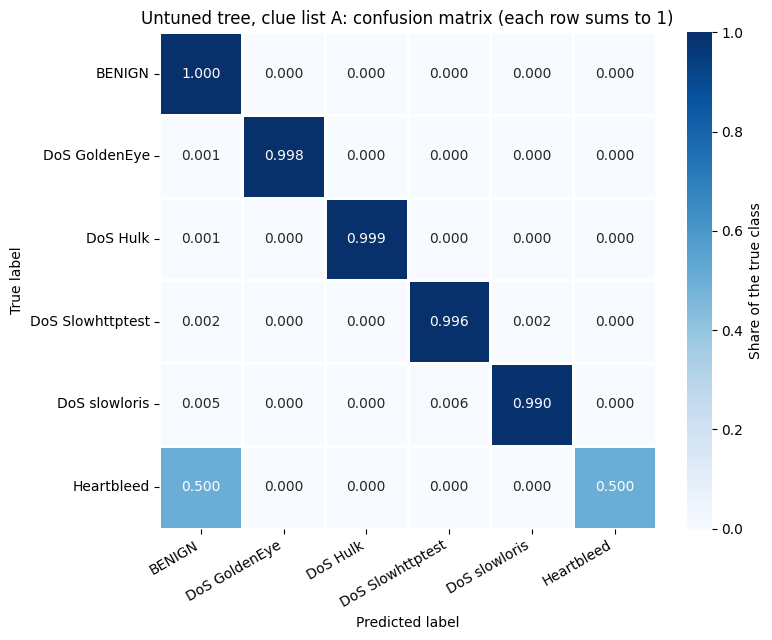

Raw counts (rows = true, columns = predicted):


,BENIGN,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,Heartbleed
BENIGN,83323,1,16,4,4,0
DoS GoldenEye,3,2052,1,1,0,0
DoS Hulk,27,1,34540,0,1,0
DoS Slowhttptest,2,0,0,1042,2,0
DoS slowloris,5,0,0,6,1066,0
Heartbleed,1,0,0,0,0,1


Lowest diagonal: Heartbleed = 0.5000 (1 of 2 test rows correct). Most often confused with BENIGN (0.5000).


In [ ]:
# Step 4 (continued) — per-class report and confusion-matrix heatmap for list A
print(classification_report(y_test, predictions["A"], labels=CLASS_LABELS, digits=4, zero_division=0))

cm = confusion_matrix(y_test, predictions["A"], labels=CLASS_LABELS)
row_totals = cm.sum(axis=1, keepdims=True)
cm_share = np.divide(cm, row_totals, out=np.zeros(cm.shape), where=row_totals > 0)  # each row: share of that true class

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm_share, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS,
            linewidths=1, linecolor="white", cbar_kws={"label": "Share of the true class"}, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Untuned tree, clue list A: confusion matrix (each row sums to 1)")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "S5_A_confusion_matrix.png", dpi=150)
plt.show()

# Raw counts too: for rare classes a share like 0.500 might be just 1 row out of 2
print("Raw counts (rows = true, columns = predicted):")
display(pd.DataFrame(cm, index=CLASS_LABELS, columns=CLASS_LABELS))

# Help with "You're done when": the row whose diagonal is furthest from 1.0
diag = np.diag(cm_share)
weakest = int(np.argmin(diag))
off_diag = cm_share[weakest].copy()
off_diag[weakest] = -1
confused_with = int(np.argmax(off_diag))
print(f"Lowest diagonal: {CLASS_LABELS[weakest]} = {diag[weakest]:.4f} "
      f"({int(cm[weakest, weakest])} of {int(row_totals[weakest, 0])} test rows correct). "
      f"Most often confused with {CLASS_LABELS[confused_with]} ({off_diag[confused_with]:.4f}).")

## Step 5 — Compare A, B, C, D

**Goal:** answer the first piece of the research question: *how much do we lose when we use fewer clues?*

**What to do:**
- Run your function from Step 4 on lists B, C and D.
- Put all four results into one table (`pandas.DataFrame`), sorted from most clues to fewest.
- Draw two small graphs: macro F1 against number of clues, and saved model size against number of clues.

**Before you look:** write in your notes whether you expect the score to fall a lot or a little as the clues shrink. Then compare.

**Do not decide anything from one run.** Just read it.

**You're done when:** you have the table and both graphs.

[B] 39 clues | acc 0.9993 | macro F1 0.9409 | attack recall 0.9989 (missed 43, false alarms 26) | 891 nodes, depth 31, 99.9 KB | train 20.71 s, predict 0.1624 ms/1000 rows
[C] 15 clues | acc 0.9993 | macro F1 0.8299 | attack recall 0.9990 (missed 38, false alarms 34) | 997 nodes, depth 31, 111.1 KB | train 6.62 s, predict 0.0794 ms/1000 rows
[D] 6 clues | acc 0.9988 | macro F1 0.9104 | attack recall 0.9982 (missed 68, false alarms 66) | 1487 nodes, depth 32, 164.5 KB | train 2.17 s, predict 0.0659 ms/1000 rows


,run,num_features,accuracy,precision_macro,recall_macro,f1_macro,attack_recall,missed,false_alarms,num_nodes,depth,model_size_kb,training_time_s,inference_ms_per_1000
0,A,57,0.9994,0.9969,0.9137,0.9414,0.9990,38,25,825,31,92.9775,27.4462,0.1935
1,B,39,0.9993,0.9966,0.9129,0.9409,0.9989,43,26,891,31,99.9150,20.7125,0.1624
2,C,15,0.9993,0.8294,0.8303,0.8299,0.9990,38,34,997,31,111.0557,6.6175,0.0794
3,D,6,0.9988,0.9098,0.9109,0.9104,0.9982,68,66,1487,32,164.4775,2.1724,0.0659


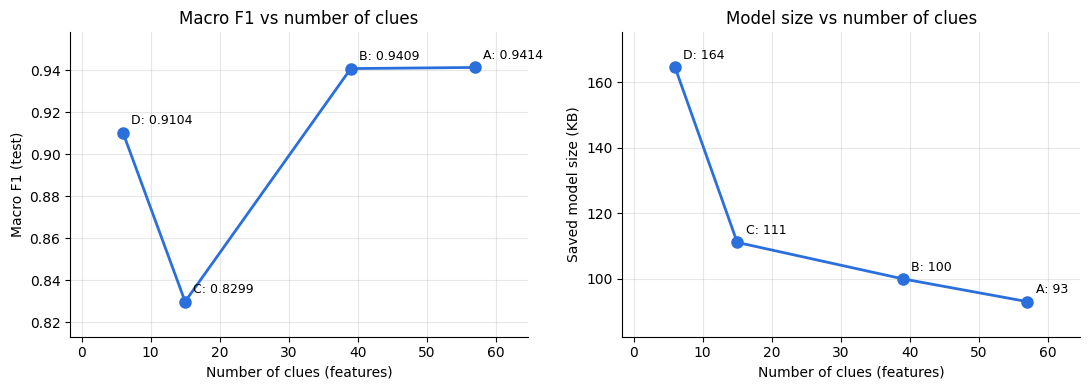

Recall for each class (which attacks get lost as the clue list shrinks?):


,test rows,A,B,C,D
BENIGN,83348,0.9997,0.9997,0.9996,0.9992
DoS GoldenEye,2057,0.9976,0.9976,0.9971,0.9869
DoS Hulk,34569,0.9992,0.9991,0.9992,0.9990
DoS Slowhttptest,1046,0.9962,0.9914,0.9962,0.9943
DoS slowloris,1077,0.9898,0.9898,0.9898,0.9861
Heartbleed,2,0.5000,0.5000,0.0000,0.5000


In [ ]:
# Step 5 — Compare A, B, C, D
# BEFORE running this cell, write your prediction in experiment_notes.md:
#   "I expect macro F1 to fall a lot / a little from A (57 clues) to D (6 clues), because ..."

for name in ["B", "C", "D"]:
    run_experiment(name, feature_sets[name])

TABLE_COLS = ["run", "num_features", "accuracy", "precision_macro", "recall_macro", "f1_macro",
              "attack_recall", "missed", "false_alarms", "num_nodes", "depth",
              "model_size_kb", "training_time_s", "inference_ms_per_1000"]


def results_table(names):
    return pd.DataFrame([results[n] for n in names])[TABLE_COLS]


compare_ABCD = results_table(["A", "B", "C", "D"]).sort_values("num_features", ascending=False)
display(compare_ABCD.round(4))

# Two small graphs, one measure each (separate charts: the two numbers have different units)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ylabel in [(axes[0], "f1_macro", "Macro F1 (test)"),
                        (axes[1], "model_size_kb", "Saved model size (KB)")]:
    ax.plot(compare_ABCD["num_features"], compare_ABCD[col], marker="o", markersize=8,
            linewidth=2, color="#2a6fdb")
    for _, r in compare_ABCD.iterrows():
        ax.annotate(f"{r['run']}: {r[col]:.4f}" if col == "f1_macro" else f"{r['run']}: {r[col]:.0f}",
                    (r["num_features"], r[col]), textcoords="offset points", xytext=(6, 6), fontsize=9)
    ax.set_xlabel("Number of clues (features)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.margins(x=0.15, y=0.15)   # room for the point labels
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_title("Macro F1 vs number of clues")
axes[1].set_title("Model size vs number of clues")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "S5_ABCD_f1_and_size.png", dpi=150)
plt.show()


def recall_table(names):
    """Recall for each true class, one column per run; 'test rows' shows how much each number rests on."""
    t = pd.DataFrame({n: results[n]["per_class_recall"] for n in names})
    t.insert(0, "test rows", pd.Series(results[names[0]]["per_class_support"]))
    return t


print("Recall for each class (which attacks get lost as the clue list shrinks?):")
display(recall_table(["A", "B", "C", "D"]).round(4))

## Step 6 — Shortcut check

**The worry (it is in your own feature table):** CICIDS2017 attacks were run from a lab against fixed ports and fixed machines. A tree might score well just by memorising *"this port or this window size means attack"* instead of learning how attacks behave. A real network would not hand us that shortcut.

**What to do:** run your function again on these clue lists, and add them to your results:

| Run name | Clues |
|---|---|
| A_no_port | list A without `Destination Port` |
| A_no_port_no_window | list A without `Destination Port`, `Init_Win_bytes_forward` and `Init_Win_bytes_backward` |
| C_no_port | list C without `Destination Port` |
| D_no_port | list D without `Destination Port` |

**How to read it:** if the score barely moves, the tree is learning behaviour. If it collapses, it was leaning on a shortcut, and that is an important finding. This is *not* choosing clues with the exam. We are asking a question about the model, not tuning it. Still, write down what you did and why.

**You're done when:** you have four more rows in your results table and one sentence in your notes about what changed.

In [ ]:
# Step 6 — Shortcut check: remove the lab-specific clues and see if the score holds
PORT = "Destination Port"
WINDOW = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]


def without(cols, drop):
    return [c for c in cols if c not in drop]


shortcut_runs = {
    "A_no_port":           (without(feature_sets["A"], [PORT]),          "A"),
    "A_no_port_no_window": (without(feature_sets["A"], [PORT] + WINDOW), "A"),
    "C_no_port":           (without(feature_sets["C"], [PORT]),          "C"),
    "D_no_port":           (without(feature_sets["D"], [PORT]),          "D"),
}
# Make sure each removal actually happened (A: 57 -> 56 -> 54, C: 15 -> 14, D: 6 -> 5)
expected_counts = {"A_no_port": 56, "A_no_port_no_window": 54, "C_no_port": 14, "D_no_port": 5}
for name, (cols, _) in shortcut_runs.items():
    assert len(cols) == expected_counts[name], f"{name} has {len(cols)} clues"

for name, (cols, _) in shortcut_runs.items():
    run_experiment(name, cols)

# Side by side with the run it came from
rows = []
for name, (_, parent) in shortcut_runs.items():
    r, p = results[name], results[parent]
    rows.append({
        "run": name, "compared with": parent,
        "macro F1": r["f1_macro"], "change in macro F1": r["f1_macro"] - p["f1_macro"],
        "attack recall": r["attack_recall"], "change in attack recall": r["attack_recall"] - p["attack_recall"],
        "missed": r["missed"], "change in missed": r["missed"] - p["missed"],
        "false alarms": r["false_alarms"], "change in false alarms": r["false_alarms"] - p["false_alarms"],
        "nodes": r["num_nodes"], "change in nodes": r["num_nodes"] - p["num_nodes"],
    })
shortcut_compare = pd.DataFrame(rows)
display(shortcut_compare.round(4))

print("Recall for each class, with and without the shortcut clues:")
display(recall_table(["A", "A_no_port", "A_no_port_no_window", "C", "C_no_port", "D", "D_no_port"]).round(4))

[A_no_port] 56 clues | acc 0.9990 | macro F1 0.9375 | attack recall 0.9985 (missed 58, false alarms 47) | 1139 nodes, depth 30, 127.3 KB | train 25.70 s, predict 0.2095 ms/1000 rows
[A_no_port_no_window] 54 clues | acc 0.9970 | macro F1 0.9377 | attack recall 0.9939 (missed 235, false alarms 115) | 2863 nodes, depth 51, 315.8 KB | train 25.25 s, predict 0.2042 ms/1000 rows
[C_no_port] 14 clues | acc 0.9989 | macro F1 0.8275 | attack recall 0.9985 (missed 60, false alarms 67) | 1607 nodes, depth 31, 177.8 KB | train 6.48 s, predict 0.0764 ms/1000 rows
[D_no_port] 5 clues | acc 0.9975 | macro F1 0.9051 | attack recall 0.9965 (missed 136, false alarms 154) | 2837 nodes, depth 33, 312.1 KB | train 2.20 s, predict 0.0720 ms/1000 rows


,run,compared with,macro F1,change in macro F1,attack recall,change in attack recall,missed,change in missed,false alarms,change in false alarms,nodes,change in nodes
0,A_no_port,A,0.9375,-0.0039,0.9985,-0.0005,58,20,47,22,1139,314
1,A_no_port_no_window,A,0.9377,-0.0037,0.9939,-0.0051,235,197,115,90,2863,2038
2,C_no_port,C,0.8275,-0.0024,0.9985,-0.0006,60,22,67,33,1607,610
3,D_no_port,D,0.9051,-0.0053,0.9965,-0.0018,136,68,154,88,2837,1350


Recall for each class, with and without the shortcut clues:


,test rows,A,A_no_port,A_no_port_no_window,C,C_no_port,D,D_no_port
BENIGN,83348,0.9997,0.9994,0.9986,0.9996,0.9992,0.9992,0.9982
DoS GoldenEye,2057,0.9976,0.9981,0.9981,0.9971,0.9966,0.9869,0.9772
DoS Hulk,34569,0.9992,0.9991,0.9940,0.9992,0.9990,0.9990,0.9982
DoS Slowhttptest,1046,0.9962,0.9713,0.9742,0.9962,0.9847,0.9943,0.9818
DoS slowloris,1077,0.9898,0.9870,0.9916,0.9898,0.9898,0.9861,0.9824
Heartbleed,2,0.5000,0.5000,0.5000,0.0000,0.0000,0.5000,0.5000


## Step 7 — Save your results

**Goal:** write your numbers in the same layout as `experiments/results.csv` in the repo.

**The columns, in this order:**
`experiment_id, date, stage, dataset_file, num_samples, num_features, features_used, max_depth, num_nodes, accuracy, precision, recall, f1, model_size_kb, training_time_s, inference_ms, ram_mb, notes`

**How to fill them:**
- `experiment_id`: for example `S5-A`, `S5-B`, `S5-A_no_port`
- `stage`: `5-baseline`
- `dataset_file`: `Wednesday-workingHours`
- `num_samples`: train rows + test rows
- `features_used`: the run name (A, B, C, D, A_no_port, ...)
- `max_depth`: the **actual** depth of the tree you got (you did not set it)
- `precision`, `recall`, `f1`: the **macro** averages
- `inference_ms`: milliseconds **per 1000 rows**, and say so in `notes`
- `ram_mb`: **leave empty.** We have not measured memory. Never guess it.
- `notes`: say it is an untuned tree, and include attack recall, missed attacks and false alarms

**Then:**
1. Save a CSV in your Drive folder.
2. Copy the rows into `experiments/results.csv` in the repo.
3. Add a dated entry to `experiments/experiment_notes.md`: what you saw and what surprised you.
4. Push, including `feature_sets.json` (put it in `experiments/`). Never push the data CSVs.

**You're done when:** the repo shows your new rows on GitHub.

In [ ]:
# Step 7 — Save the results in the same layout as experiments/results.csv
RESULTS_COLUMNS = ["experiment_id", "date", "stage", "dataset_file", "num_samples", "num_features",
                   "features_used", "max_depth", "num_nodes", "accuracy", "precision", "recall", "f1",
                   "model_size_kb", "training_time_s", "inference_ms", "ram_mb", "notes"]
RUN_ORDER = ["A", "B", "C", "D", "A_no_port", "A_no_port_no_window", "C_no_port", "D_no_port"]
today = datetime.date.today().isoformat()

rows = []
for name in RUN_ORDER:
    r = results[name]
    rows.append({
        "experiment_id": f"S5-{name}",
        "date": today,
        "stage": "5-baseline",
        "dataset_file": "Wednesday-workingHours",
        "num_samples": len(X_train) + len(X_test),
        "num_features": r["num_features"],
        "features_used": name,
        "max_depth": r["depth"],                 # the depth the tree grew to, not a setting
        "num_nodes": r["num_nodes"],
        "accuracy": round(r["accuracy"], 6),
        "precision": round(r["precision_macro"], 6),
        "recall": round(r["recall_macro"], 6),
        "f1": round(r["f1_macro"], 6),
        "model_size_kb": round(r["model_size_kb"], 2),
        "training_time_s": round(r["training_time_s"], 3),
        "inference_ms": round(r["inference_ms_per_1000"], 4),
        "ram_mb": "",                            # not measured, so left empty on purpose
        "notes": (f"untuned DecisionTreeClassifier(random_state=42); precision/recall/f1 are macro; "
                  f"inference_ms = ms per 1000 test rows (median of {N_PREDICT_REPEATS} predict runs); "
                  f"attack recall={r['attack_recall']:.6f}; missed attacks={r['missed']}; "
                  f"false alarms={r['false_alarms']}"),
    })
results_df = pd.DataFrame(rows, columns=RESULTS_COLUMNS)

# 1. Save CSVs in your Drive folder
out_csv = RESULTS_DIR / "S5_baseline_results.csv"
results_df.to_csv(out_csv, index=False)
recall_table(RUN_ORDER).to_csv(RESULTS_DIR / "S5_per_class_recall.csv")
with open(RESULTS_DIR / "feature_sets.json", "w") as f:   # copy for the repo's experiments/ folder
    json.dump(feature_sets, f, indent=4)
print("Saved:", out_csv)
print("Saved:", RESULTS_DIR / "S5_per_class_recall.csv")
print("Saved:", RESULTS_DIR / "feature_sets.json")
display(results_df)

# 2. Rows to paste under the header of experiments/results.csv in the repo
print("\n----- paste these rows into experiments/results.csv -----")
print(results_df.to_csv(index=False, header=False), end="")

# 3. A starting point for experiment_notes.md: the facts are filled in, the thinking is yours
a, d = results["A"], results["D"]
print(f"""
----- draft entry for experiments/experiment_notes.md -----
### {today} — Stage 5 baseline (untuned decision tree)

**Dataset file used:** Wednesday-workingHours, {len(X_train)} train + {len(X_test)} test rows
**What I did:** untuned DecisionTreeClassifier(random_state=42) on lists A/B/C/D (57/39/15/6 clues)
plus 4 shortcut-check runs without Destination Port (and Init_Win_bytes for A).
**What I observed:** A: macro F1 {a['f1_macro']:.4f}, attack recall {a['attack_recall']:.4f}, {a['num_nodes']} nodes, {a['model_size_kb']:.1f} KB.
D: macro F1 {d['f1_macro']:.4f}, attack recall {d['attack_recall']:.4f}, {d['num_nodes']} nodes, {d['model_size_kb']:.1f} KB.
Shortcut check: <one sentence on what changed>
**What surprised me:** <...>
**Any errors/problems:** <...>
**Next step:** <...>
""")

Saved: /content/drive/MyDrive/Colab Notebooks/threat detector/experiments/S5_baseline_results.csv
Saved: /content/drive/MyDrive/Colab Notebooks/threat detector/experiments/S5_per_class_recall.csv
Saved: /content/drive/MyDrive/Colab Notebooks/threat detector/experiments/feature_sets.json


,experiment_id,date,stage,dataset_file,num_samples,num_features,features_used,max_depth,num_nodes,accuracy,precision,recall,f1,model_size_kb,training_time_s,inference_ms,ram_mb,notes
0,S5-A,2026-10-22,5-baseline,Wednesday-workingHours,610492,57,A,31,825,0.999386,0.996851,0.913732,0.941400,92.98,27.446,0.1935,,untuned DecisionTreeClassifier(random_state=42...
1,S5-B,2026-10-22,5-baseline,Wednesday-workingHours,610492,39,B,31,891,0.999320,0.996589,0.912924,0.940867,99.92,20.712,0.1624,,untuned DecisionTreeClassifier(random_state=42...
2,S5-C,2026-10-22,5-baseline,Wednesday-workingHours,610492,15,C,31,997,0.999296,0.829447,0.830300,0.829870,111.06,6.618,0.0794,,untuned DecisionTreeClassifier(random_state=42...
3,S5-D,2026-10-22,5-baseline,Wednesday-workingHours,610492,6,D,32,1487,0.998780,0.909839,0.910906,0.910370,164.48,2.172,0.0659,,untuned DecisionTreeClassifier(random_state=42...
4,S5-A_no_port,2026-10-22,5-baseline,Wednesday-workingHours,610492,56,A_no_port,30,1139,0.998968,0.993636,0.909157,0.937504,127.31,25.703,0.2095,,untuned DecisionTreeClassifier(random_state=42...
5,S5-A_no_port_no_window,2026-10-22,5-baseline,Wednesday-workingHours,610492,54,A_no_port_no_window,51,2863,0.997011,0.993750,0.909410,0.937688,315.81,25.246,0.2042,,untuned DecisionTreeClassifier(random_state=42...
6,S5-C_no_port,2026-10-22,5-baseline,Wednesday-workingHours,610492,14,C_no_port,31,1607,0.998862,0.826815,0.828207,0.827509,177.76,6.482,0.0764,,untuned DecisionTreeClassifier(random_state=42...
7,S5-D_no_port,2026-10-22,5-baseline,Wednesday-workingHours,610492,5,D_no_port,33,2837,0.997535,0.903925,0.906289,0.905102,312.12,2.203,0.0720,,untuned DecisionTreeClassifier(random_state=42...



----- paste these rows into experiments/results.csv -----
S5-A,2026-10-22,5-baseline,Wednesday-workingHours,610492,57,A,31,825,0.999386,0.996851,0.913732,0.9414,92.98,27.446,0.1935,,untuned DecisionTreeClassifier(random_state=42); precision/recall/f1 are macro; inference_ms = ms per 1000 test rows (median of 5 predict runs); attack recall=0.999019; missed attacks=38; false alarms=25
S5-B,2026-10-22,5-baseline,Wednesday-workingHours,610492,39,B,31,891,0.99932,0.996589,0.912924,0.940867,99.92,20.712,0.1624,,untuned DecisionTreeClassifier(random_state=42); precision/recall/f1 are macro; inference_ms = ms per 1000 test rows (median of 5 predict runs); attack recall=0.998890; missed attacks=43; false alarms=26
S5-C,2026-10-22,5-baseline,Wednesday-workingHours,610492,15,C,31,997,0.999296,0.829447,0.8303,0.82987,111.06,6.618,0.0794,,untuned DecisionTreeClassifier(random_state=42); precision/recall/f1 are macro; inference_ms = ms per 1000 test rows (median of 5 predict runs); attack recall=0.

## Step 8 — Read your numbers honestly

Check each of these before you write any conclusion:

- **A very high score?** Don't celebrate yet. You split one day of traffic at random, so near-identical rows from the same attack burst can land in both piles. A high score here does not prove it would work on a different day or a different network.
- **Rare attack classes.** A class with only a handful of test rows (Heartbleed has very few) can swing wildly. Report it, but don't build a claim on it.
- **Compare attack recall with accuracy.** Missing real attacks matters more than a few false alarms.
- **Did the shortcut check change things?** If yes, say so plainly. That is a finding, not a failure.
- **Never write a number you did not see on screen.**

## What comes next (do not start yet)

The next stage shrinks the tree on purpose and watches what happens to these same numbers. A good question to bring: *at which point does the score start to fall faster than the size does?*

In [ ]:
# Step 8 — Facts to look at before writing any conclusion (this cell only prints; the reading is yours)

# 1. Rare classes: how many test rows is each per-class number built on?
support = pd.Series(results["A"]["per_class_support"]).sort_values()
print("Test rows per class:")
print(support.to_string())
tiny = support[support < 50]
if len(tiny):
    print(f"-> Fewer than 50 test rows: {', '.join(tiny.index)}. "
          "One extra mistake moves their recall a lot; report them, but don't build a claim on them.")

# 2. Accuracy next to attack recall (missing a real attack is the worst mistake)
print("\nAccuracy vs attack recall:")
display(pd.DataFrame([results[n] for n in RUN_ORDER])[
    ["run", "num_features", "accuracy", "attack_recall", "missed", "false_alarms"]].round(6))

# 3. Did the shortcut check change things?
print("Shortcut check (change in macro F1 and attack recall vs the parent run):")
display(shortcut_compare[["run", "compared with", "change in macro F1", "change in attack recall",
                          "change in missed"]].round(6))

print("Reminder: this is ONE day of traffic split at random, so near-identical rows from the same "
      "attack burst can sit in both piles. A high score here does not show it would work on another day "
      "or another network.")

Test rows per class:
Heartbleed              2
DoS Slowhttptest     1046
DoS slowloris        1077
DoS GoldenEye        2057
DoS Hulk            34569
BENIGN              83348
-> Fewer than 50 test rows: Heartbleed. One extra mistake moves their recall a lot; report them, but don't build a claim on them.

Accuracy vs attack recall:


,run,num_features,accuracy,attack_recall,missed,false_alarms
0,A,57,0.999386,0.999019,38,25
1,B,39,0.999320,0.998890,43,26
2,C,15,0.999296,0.999019,38,34
3,D,6,0.998780,0.998245,68,66
4,A_no_port,56,0.998968,0.998503,58,47
5,A_no_port_no_window,54,0.997011,0.993936,235,115
6,C_no_port,14,0.998862,0.998452,60,67
7,D_no_port,5,0.997535,0.996490,136,154


Shortcut check (change in macro F1 and attack recall vs the parent run):


,run,compared with,change in macro F1,change in attack recall,change in missed
0,A_no_port,A,-0.003896,-0.000516,20
1,A_no_port_no_window,A,-0.003712,-0.005084,197
2,C_no_port,C,-0.002362,-0.000568,22
3,D_no_port,D,-0.005268,-0.001755,68


Reminder: this is ONE day of traffic split at random, so near-identical rows from the same attack burst can sit in both piles. A high score here does not show it would work on another day or another network.
